<h1 align="center">E-Commerce Customer Segmentation</h1>
<h3 align="center"> Customer Features</h3>

**Project:** E-Commerce Customer Segmentation: RFM and K-Means Analysis of Who Drives, and Who Threatens, Revenue

This notebook is the foundation for the rest of the analysis. It does three things:

1. **Continuity check.** Confirms that the data in this repository reproduces the headline figures published in the first project, [e-commerce-sales-analytics](https://github.com/Vin-Okumu/e-commerce-sales-analytics), before anything new is calculated.
2. **Data questions.** Answers the nine questions listed under *"Data questions to answer first (NB01)"* in the [analysis charter](../02_documentation/analysis_charter.md). Their answers decide how the features are built.
3. **Customer feature table.** Builds one row per customer for the full period (snapshot 30 Jun 2026) and for the calibration period (snapshot 31 Dec 2025), checks feature quality, and saves both tables for the later notebooks.

**Source tags.** Figures quoted from the first project are tagged *[Report §x]* or *[Dictionary]*. Every other figure in this notebook is calculated here and is cited elsewhere in the repository as *[NB01]*.

| Input | Output |
|---|---|
| `01_data/processed/Fact_Sales.csv`, `Dim_Customers.csv`, `Dim_Products.csv` | `01_data/output/customer_features_full.csv` |
| | `01_data/output/customer_features_calibration.csv` |
| | `04_report/figures/nb01_*.png` |

## 1. Setup

Libraries are imported in the cell where they are first needed, so it is clear which library each step depends on.

In [1]:
# pathlib: build file paths that work on Windows, macOS and Linux
from pathlib import Path

# pandas: read the CSV files and work with tables
import pandas as pd

# customer_features.py (this folder): shared loading and feature-building rules used by every notebook
import customer_features as cf

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("../01_data/processed")
OUTPUT_DIR = Path("../01_data/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fact, customers, products = cf.load_data(DATA_DIR)
print(f"Fact_Sales: {len(fact):,} orders | Dim_Customers: {len(customers):,} | Dim_Products: {len(products):,}")
print(f"Order dates: {fact.order_date.min():%d %b %Y} to {fact.order_date.max():%d %b %Y}")

Fact_Sales: 250,000 orders | Dim_Customers: 40,000 | Dim_Products: 2,000
Order dates: 01 Jun 2024 to 30 Jun 2026


## 2. Continuity check against the first project

Before any new analysis, the data must reproduce what the first project published. The first project's measures count **every order status** (its NTV includes cancelled and returned orders, *[Report §5]*), so the same rule is used here. The reporting period is Jan–Jun 2026, compared with Jan–Jun 2025.

In [2]:
# numpy: compare published and reproduced figures within a rounding tolerance
import numpy as np

h1_26 = fact[(fact.order_date >= "2026-01-01") & (fact.order_date <= "2026-06-30")]
h1_25 = fact[(fact.order_date >= "2025-01-01") & (fact.order_date <= "2025-06-30")]

orders_per_cust_h1 = h1_26.groupby("customer_id").size()
ntv_h1 = h1_26.total_amount.sum()

reproduced = pd.DataFrame([
    ("Orders in Fact_Sales",               250_000,  len(fact),                                   "Dictionary"),
    ("Customers with at least one order",   39_914,  fact.customer_id.nunique(),                  "Dictionary"),
    ("NTV, Jan–Jun 2026 (₹ M)",            1_413.0,  ntv_h1 / 1e6,                                 "Report §3.3"),
    ("Orders, Jan–Jun 2026",                59_340,  len(h1_26),                                   "Report §3.1"),
    ("Active customers, Jan–Jun 2026",      30_840,  h1_26.customer_id.nunique(),                 "Report §3.1"),
    ("AOV, Jan–Jun 2026 (₹)",               23_812,  ntv_h1 / len(h1_26),                          "Report §3.1"),
    ("Repeat customers (2+ orders)",        17_436,  (orders_per_cust_h1 > 1).sum(),               "Report §3.4"),
    ("One-time customers",                  13_404,  (orders_per_cust_h1 == 1).sum(),              "Report §3.4"),
    ("YoY NTV change vs Jan–Jun 2025 (%)",   -0.07,  (ntv_h1 / h1_25.total_amount.sum() - 1) * 100, "Report §1"),
    ("Electronics share of NTV (%)",          72.7,  h1_26.loc[h1_26.category == "Electronics", "total_amount"].sum() / ntv_h1 * 100, "Report §3.2"),
    ("Coupon discounts (₹ M)",                14.8,  h1_26.coupon_discount.sum() / 1e6,             "Report §3.2"),
    ("Coupon discount rate (%)",              1.04,  h1_26.coupon_discount.sum() / h1_26.order_value.sum() * 100, "Report §3.2"),
], columns=["Metric", "Published", "Reproduced", "Source"])

# Published figures are rounded, so allow for rounding in the last published digit
reproduced["Match"] = np.isclose(reproduced.Published, reproduced.Reproduced, rtol=0.001, atol=0.051)
assert reproduced.Match.all(), "Data does not reproduce the first project's published figures"
reproduced

,Metric,Published,Reproduced,Source,Match
0,Orders in Fact_Sales,"250,000.00","250,000.00",Dictionary,True
1,Customers with at least one order,"39,914.00","39,914.00",Dictionary,True
2,"NTV, Jan–Jun 2026 (₹ M)","1,413.00","1,413.03",Report §3.3,True
3,"Orders, Jan–Jun 2026","59,340.00","59,340.00",Report §3.1,True
4,"Active customers, Jan–Jun 2026","30,840.00","30,840.00",Report §3.1,True
5,"AOV, Jan–Jun 2026 (₹)","23,812.00","23,812.39",Report §3.1,True
6,Repeat customers (2+ orders),"17,436.00","17,436.00",Report §3.4,True
7,One-time customers,"13,404.00","13,404.00",Report §3.4,True
8,YoY NTV change vs Jan–Jun 2025 (%),-0.07,-0.07,Report §1,True
9,Electronics share of NTV (%),72.70,72.65,Report §3.2,True


**Finding:** all 12 published figures are reproduced. The small differences (for example NTV ₹1,413.03 M against the published ₹1,413.0 M, or Electronics 72.65% against 72.7%) are rounding in the published report. This repository therefore starts from exactly the same data as the first project, and every new figure below can be compared with the first project's figures directly.

## 3. Data questions

Each question comes from the analysis charter. The answers are used in Section 4 to decide how each feature is built.

Unless stated otherwise, "full period" means 1 Jun 2024 to 30 Jun 2026, and the order-status rule is stated for each question.

### Q1. How many orders does each customer place over the full 25 months, and how many have only one order in their whole history?

*All order statuses (an order placed is a purchase decision, whatever happened to it afterwards).*

count   39,914.00
mean         6.26
std          2.48
min          1.00
25%          4.00
50%          6.00
75%          8.00
max         19.00

Customers with exactly one order in 25 months: 483 (1.2% of 39,914)


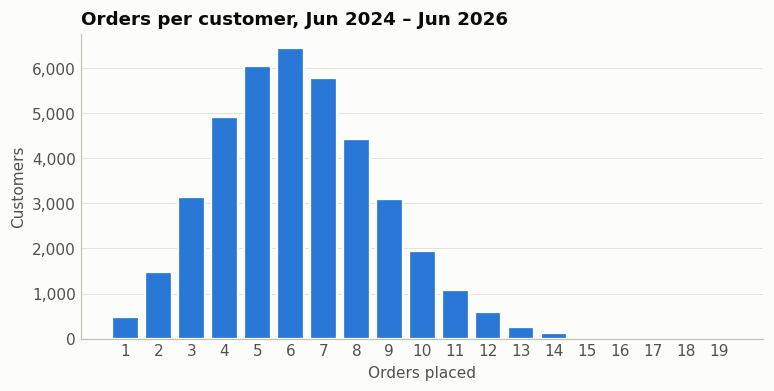

In [3]:
orders_per_customer = fact.groupby("customer_id").size()
print(orders_per_customer.describe().round(2).to_string())
print(f"\nCustomers with exactly one order in 25 months: {(orders_per_customer == 1).sum():,} "
      f"({(orders_per_customer == 1).mean():.1%} of {len(orders_per_customer):,})")

# matplotlib: draw the charts; FuncFormatter formats axis numbers (thousands separators, ₹)
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# plot_style.py (this folder): shared colours and chart defaults for every notebook
import plot_style as ps
ps.apply()

fig, ax = plt.subplots(figsize=(8, 3.6))
counts = orders_per_customer.value_counts().sort_index()
ax.bar(counts.index, counts.values, width=0.8, **ps.bar_kwargs())
ax.set_title("Orders per customer, Jun 2024 – Jun 2026")
ax.set_xlabel("Orders placed")
ax.set_ylabel("Customers")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xticks(counts.index)
ps.save(fig, "nb01_orders_per_customer")
plt.show()

**Finding:** customers placed a mean of **6.26 orders** (median 6) over the 25 months, and only **483 customers (1.2%)** placed a single order in their whole history. On average a customer orders about once every four months (25 months ÷ 6.26 orders).

**Implication:** almost every customer is already a repeat buyer over the full history. With roughly one order every four months, a six-month window will often catch only one order from a perfectly regular customer. The useful question for this business is therefore not *"will they buy a second time?"* but *"are they still buying at their usual pace?"*. That makes **Recency** the central RFM signal.

### Q2. Of the 13,404 customers who bought once in Jan–Jun 2026 *[Report §3.4]*, how many had bought before?

In [4]:
one_time_h1 = orders_per_cust_h1[orders_per_cust_h1 == 1].index
before_2026 = fact[fact.order_date < "2026-01-01"].groupby("customer_id").size()
prior_orders = before_2026.reindex(one_time_h1, fill_value=0)

print(f"One-time customers in Jan–Jun 2026: {len(one_time_h1):,}")
print(f"  ...who had ordered before 2026:     {(prior_orders > 0).sum():,} ({(prior_orders > 0).mean():.1%})")
print(f"  ...whose first ever order was in Jan–Jun 2026: {(prior_orders == 0).sum():,}")
print(f"\nOrders placed before 2026 by these customers:")
print(prior_orders.describe().round(2).to_string())

One-time customers in Jan–Jun 2026: 13,404
  ...who had ordered before 2026:     13,287 (99.1%)
  ...whose first ever order was in Jan–Jun 2026: 117

Orders placed before 2026 by these customers:
count   13,404.00
mean         4.74
std          2.17
min          0.00
25%          3.00
50%          5.00
75%          6.00
max         15.00


**Finding:** of the 13,404 customers who placed one order in Jan–Jun 2026 *[Report §3.4]*, **13,287 (99.1%) had ordered before 2026**, with a median of 5 earlier orders. Only **117** placed their first ever order in that period.

**Implication:** the first project correctly counted these customers as one-time buyers *within its six-month reporting window*. Over the full history, though, nearly all of them are established customers buying at a slower pace, not new customers who failed to return. A second-purchase offer for first-time buyers *[Report §4]* would reach very few genuinely new customers. Re-engaging established customers whose buying has slowed is the more relevant action, and it is what the lapse-risk analysis in NB04 measures.

### Q3. How many customers who ordered between Jun 2024 and Dec 2025 placed no order in Jan–Jun 2026?

*All order statuses.* This is the group that the holdout validation in NB04 tries to predict.

In [5]:
calib_customers = set(fact.loc[fact.order_date <= cf.CALIBRATION_END, "customer_id"])
holdout_customers = set(h1_26.customer_id)
lapsed = calib_customers - holdout_customers

calib_valid = fact[(fact.order_date <= cf.CALIBRATION_END) & fact.order_status.isin(cf.VALID_STATUSES)]
calib_spend = calib_valid.groupby("customer_id").total_amount.sum()

print(f"Customers who ordered Jun 2024 – Dec 2025:          {len(calib_customers):,}")
print(f"  ...and ordered again in Jan–Jun 2026:             {len(calib_customers & holdout_customers):,}")
print(f"  ...and placed no order in Jan–Jun 2026:           {len(lapsed):,} ({len(lapsed) / len(calib_customers):.1%})")
print(f"Customers whose first order was in Jan–Jun 2026:    {len(holdout_customers - calib_customers):,}")
print(f"\nValid-order spend Jun 2024 – Dec 2025 by customers with no 2026 order: "
      f"₹{calib_spend.reindex(list(lapsed)).sum() / 1e6:,.1f} M "
      f"({calib_spend.reindex(list(lapsed)).sum() / calib_spend.sum():.1%} of calibration spend)")

Customers who ordered Jun 2024 – Dec 2025:          39,640
  ...and ordered again in Jan–Jun 2026:             30,566
  ...and placed no order in Jan–Jun 2026:           9,074 (22.9%)
Customers whose first order was in Jan–Jun 2026:    274

Valid-order spend Jun 2024 – Dec 2025 by customers with no 2026 order: ₹953.9 M (23.5% of calibration spend)


**Finding:** **39,640** customers ordered between Jun 2024 and Dec 2025. Of these, **9,074 (22.9%) placed no order in Jan–Jun 2026**. Their valid-order spend in the calibration period was **₹953.9 M**, 23.5% of all calibration spend. A further **274** customers placed their first order in Jan–Jun 2026.

**Implication:** about one customer in four went quiet for the whole of the latest six months, and they were not low-value customers: their share of spend (23.5%) is in line with their share of customers (22.9%). This is the group the holdout validation in NB04 will try to predict from end-of-2025 behaviour.

### Q4. How is Recency distributed at the 30 Jun 2026 snapshot?

*Recency = days from the last order placed (any status) to 30 Jun 2026.*

count   39,914.00
mean       120.00
std        117.00
min          0.00
10%         12.00
25%         34.00
50%         84.00
75%        169.00
90%        278.00
max        758.00


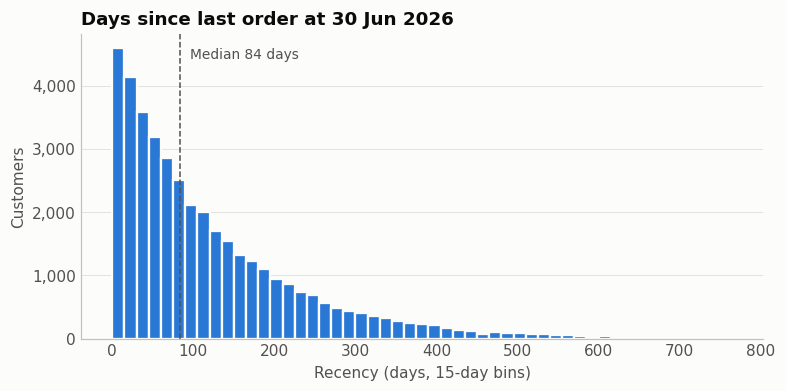

In [6]:
last_order = fact.groupby("customer_id").order_date.max()
recency = (cf.FULL_END - last_order).dt.days
print(recency.describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(recency, bins=range(0, int(recency.max()) + 15, 15), **ps.bar_kwargs())
ax.axvline(recency.median(), color=ps.TEXT_SECONDARY, linewidth=1, linestyle="--")
ax.annotate(f"Median {recency.median():.0f} days", xy=(recency.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=ps.TEXT_SECONDARY, fontsize=9)
ax.set_title("Days since last order at 30 Jun 2026")
ax.set_xlabel("Recency (days, 15-day bins)")
ax.set_ylabel("Customers")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ps.save(fig, "nb01_recency_distribution")
plt.show()

**Finding:** at 30 Jun 2026 the median customer last ordered **84 days** earlier. A quarter ordered within the last 34 days and a quarter had not ordered for more than 169 days; 10% had not ordered for over 278 days. The distribution has a long right tail (maximum 758 days).

**Implication:** Recency has a wide, usable spread for separating active customers from lapsing ones. Its long tail (skewness 1.69 among buyers, Section 4.3) means a transformation should be tested in NB03 so that a few very inactive customers do not dominate the distance calculation.

### Q5. How skewed is spend per customer, and does it need a log transformation?

*Monetary = sum of `total_amount` on valid orders (Delivered, Shipped, Processing).*

count    39,848.00
mean    133,712.00
std     113,804.00
min          94.00
10%      17,634.00
25%      46,834.00
50%     104,749.00
75%     190,148.00
90%     290,514.00
99%     501,461.00
max     906,815.00

Skewness, raw:         1.40
Skewness, log(1 + x):   -1.18
Share of spend from the top 10% of customers: 28.8%


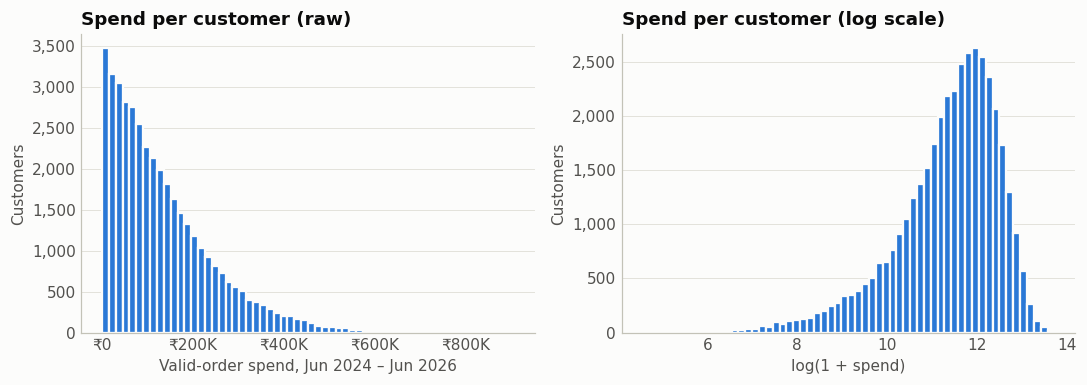

In [7]:
valid = fact[fact.order_status.isin(cf.VALID_STATUSES)]
monetary = valid.groupby("customer_id").total_amount.sum()
print(monetary.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(0).to_string())

# scipy.stats: skewness here, and the statistical tests used in Q8 and Q9
from scipy import stats

print(f"\nSkewness, raw:         {stats.skew(monetary):.2f}")
print(f"Skewness, log(1 + x):   {stats.skew(np.log1p(monetary)):.2f}")
top10 = monetary.sort_values(ascending=False)
print(f"Share of spend from the top 10% of customers: {top10.head(len(top10) // 10).sum() / top10.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(monetary, bins=60, **ps.bar_kwargs())
axes[0].set_title("Spend per customer (raw)")
axes[0].xaxis.set_major_formatter(FuncFormatter(ps.rupees))
axes[0].set_xlabel("Valid-order spend, Jun 2024 – Jun 2026")
axes[1].hist(np.log1p(monetary), bins=60, **ps.bar_kwargs())
axes[1].set_title("Spend per customer (log scale)")
axes[1].set_xlabel("log(1 + spend)")
for ax in axes:
    ax.set_ylabel("Customers")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.tight_layout()
ps.save(fig, "nb01_spend_distribution")
plt.show()

**Finding:** valid-order spend per customer ranges from ₹94 to ₹906,815, with a median of **₹104,749** and a mean of ₹133,712. The 10th percentile is ₹17,634 and the 90th is ₹290,514. Skewness is **1.40** on the raw scale and **−1.18** after a log transformation. The top 10% of customers produce **28.8%** of spend.

**Implication:** Monetary is right-skewed, so it is log-transformed before clustering, as planned in the charter. The log scale over-corrects slightly (a left tail of very low spenders), so the scaled distribution will be checked again in NB03. Spend is concentrated, but less than a classic 80/20 pattern.

### Q6. What share of orders (not revenue) is Electronics, and how many customers never buy Electronics or buy nothing else?

*Valid orders, full period.*

In [8]:
cat = valid.groupby("category").agg(orders=("order_id", "count"), revenue=("total_amount", "sum"))
cat["share_of_orders"] = cat.orders / cat.orders.sum()
cat["share_of_revenue"] = cat.revenue / cat.revenue.sum()
cat["avg_order_value"] = cat.revenue / cat.orders
display(cat.sort_values("revenue", ascending=False)[["orders", "share_of_orders", "share_of_revenue", "avg_order_value"]]
        .style.format({"orders": "{:,.0f}", "share_of_orders": "{:.1%}", "share_of_revenue": "{:.1%}", "avg_order_value": "₹{:,.0f}"}))

elec_share = valid.assign(e=valid.category.eq("Electronics")).groupby("customer_id").e.mean()
print(f"Customers with valid orders: {len(elec_share):,}")
print(f"  never buy Electronics:      {(elec_share == 0).sum():,} ({(elec_share == 0).mean():.1%})")
print(f"  buy only Electronics:       {(elec_share == 1).sum():,} ({(elec_share == 1).mean():.1%})")
print(f"  Electronics > 50% of orders: {(elec_share > 0.5).sum():,} ({(elec_share > 0.5).mean():.1%})")

,orders,share_of_orders,share_of_revenue,avg_order_value
category,,,,
Electronics,"60,117",26.7%,72.6%,"₹64,375"
Home,"30,299",13.5%,12.1%,"₹21,270"
Sports,"26,337",11.7%,8.0%,"₹16,159"
Fashion,"44,783",19.9%,5.6%,"₹6,681"
Grocery,"30,153",13.4%,0.7%,"₹1,251"
Beauty,"15,068",6.7%,0.6%,"₹2,283"
Books,"18,243",8.1%,0.3%,₹918


Customers with valid orders: 39,848
  never buy Electronics:      12,758 (32.0%)
  buy only Electronics:       677 (1.7%)
  Electronics > 50% of orders: 4,992 (12.5%)


**Finding:** Electronics is **26.7% of valid orders but 72.6% of valid-order revenue**, because its average order value (₹64,375) is three times that of the next category, Home (₹21,270). Among the 39,848 customers with valid orders, **12,758 (32.0%) never buy Electronics**, **677 (1.7%) buy only Electronics**, and **4,992 (12.5%)** have Electronics as more than half of their orders.

**Implication:** Electronics share separates customers clearly and is closely tied to how much they spend per order (Section 4.4). The 4,992 Electronics-led customers are the first candidate group for the cross-sell analysis in NB05.

### Q7. How many distinct categories does each customer buy from?

*Valid orders, full period. There are 7 categories in total.*

In [9]:
breadth = valid.groupby("customer_id").category.nunique()
breadth_table = breadth.value_counts().sort_index().rename("customers").to_frame()
breadth_table["share"] = breadth_table.customers / breadth_table.customers.sum()
display(breadth_table.style.format({"customers": "{:,.0f}", "share": "{:.1%}"}))

# Is the 3-category ceiling caused by customers ordering too few times?
check = pd.DataFrame({"breadth": breadth, "valid_orders": valid.groupby("customer_id").size()})
print("Median valid orders by number of categories bought:")
print(check.groupby("breadth").valid_orders.median().to_string())
print(f"\nCustomers with 4+ valid orders but only 1-3 categories: "
      f"{((check.valid_orders >= 4) & (check.breadth <= 3)).sum():,} of {(check.valid_orders >= 4).sum():,}")

,customers,share
category,,
1,"2,398",6.0%
2,"13,186",33.1%
3,"24,264",60.9%


Median valid orders by number of categories bought:
breadth
1   2.00
2   4.00
3   6.00

Customers with 4+ valid orders but only 1-3 categories: 32,547 of 32,547


**Finding:** **60.9%** of customers buy from 3 categories, **33.1%** from 2 and **6.0%** from 1. **No customer buys from more than 3 of the 7 categories**, and this is not because customers order too rarely: every one of the 32,547 customers with 4 or more valid orders still buys from 3 categories or fewer.

**Implication:** each customer appears to have a fixed set of up to three preferred categories. That is a strong behavioural pattern, but its hard ceiling also looks like a feature of how the data was generated (the first project already flagged the data as likely synthetic, *[Report §5]*). Category breadth is kept as a feature, with only three possible values, and this ceiling is noted as a limitation.

### Q8. How does order value differ between coupon and non-coupon orders, and how many customers never use a coupon?

*All order statuses (a coupon is applied when the order is placed). Order value is the gross `order_value`, before the coupon is deducted, so the comparison shows whether coupon orders are bigger baskets.*

In [10]:
by_coupon = fact.groupby("coupon_used").order_value.agg(orders="count", mean="mean", median="median")
display(by_coupon.style.format({"orders": "{:,.0f}", "mean": "₹{:,.0f}", "median": "₹{:,.0f}"}))

coupon_orders = fact.loc[fact.coupon_used == "Yes", "order_value"]
no_coupon_orders = fact.loc[fact.coupon_used == "No", "order_value"]
# scipy.stats (imported in Q5): Mann-Whitney U compares the two groups without assuming normal order values
u = stats.mannwhitneyu(coupon_orders, no_coupon_orders, alternative="two-sided")
print(f"Mann-Whitney U test, coupon vs no-coupon order value: p = {u.pvalue:.3f}")

by_code = fact[fact.coupon_used == "Yes"].groupby("coupon_code").order_value.agg(orders="count", mean="mean", median="median")
display(by_code.style.format({"orders": "{:,.0f}", "mean": "₹{:,.0f}", "median": "₹{:,.0f}"}))

coupon_rate = fact.assign(c=fact.coupon_used.eq("Yes")).groupby("customer_id").c.mean()
print(f"Customers who never used a coupon: {(coupon_rate == 0).sum():,} ({(coupon_rate == 0).mean():.1%})")
print(f"Customers who used a coupon on every order: {(coupon_rate == 1).sum():,}")
print(coupon_rate.describe().round(2).to_string())

,orders,mean,median
coupon_used,,,
No,"199,815","₹23,884","₹8,354"
Yes,"50,185","₹24,300","₹8,587"


Mann-Whitney U test, coupon vs no-coupon order value: p = 0.022


,orders,mean,median
coupon_code,,,
DIWALI100,"12,609","₹24,500","₹8,653"
FLAT50,"12,579","₹24,204","₹8,881"
SAVE10,"24,997","₹24,247","₹8,500"


Customers who never used a coupon: 11,276 (28.3%)
Customers who used a coupon on every order: 198
count   39,914.00
mean         0.20
std          0.18
min          0.00
25%          0.00
50%          0.18
75%          0.33
max          1.00


**Finding:** coupon orders average **₹24,300** gross order value against **₹23,884** for orders without a coupon (medians ₹8,587 and ₹8,354), a difference of about 1.7%. The difference is statistically significant (Mann-Whitney U, p = 0.022), but with 250,000 orders even a very small gap reaches significance, so it is not commercially meaningful. The three coupon codes produce similar order values (₹24,204–₹24,500). **11,276 customers (28.3%) never used a coupon** and 198 used one on every order. The typical customer uses a coupon on about one order in five (median coupon rate 0.18).

**Implication:** coupons do not lead to noticeably bigger baskets. Whether they are linked to customers continuing to buy is the open question for NB05. Coupon rate varies enough between customers to be a clustering feature.

### Q9. Does the cancel/return rate differ by payment method?

*All order statuses. Cancel/return = Cancelled or Returned.*

In [11]:
pay = fact.assign(failed=fact.order_status.isin(cf.FAILED_STATUSES))
pay_table = pay.groupby("payment_mode").agg(orders=("order_id", "count"), cancel_return_rate=("failed", "mean"))
pay_table["share_of_orders"] = pay_table.orders / pay_table.orders.sum()
display(pay_table.sort_values("orders", ascending=False)
        .style.format({"orders": "{:,.0f}", "cancel_return_rate": "{:.2%}", "share_of_orders": "{:.1%}"}))

# scipy.stats (imported in Q5): chi-square test of whether order failure depends on payment method
chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(pay.payment_mode, pay.failed))
print(f"Chi-square test of independence: chi2 = {chi2:.2f}, df = {dof}, p = {p:.3f}")

cod_share = fact.assign(c=fact.payment_mode.eq("COD")).groupby("customer_id").c.mean()
print("\nCOD share of orders per customer:")
print(cod_share.describe().round(2).to_string())

,orders,cancel_return_rate,share_of_orders
payment_mode,,,
UPI,"128,474",9.98%,51.4%
COD,"82,093",10.00%,32.8%
Debit Card,"28,856",10.05%,11.5%
Credit Card,"10,577",10.12%,4.2%


Chi-square test of independence: chi2 = 0.29, df = 3, p = 0.962

COD share of orders per customer:
count   39,914.00
mean         0.33
std          0.22
min          0.00
25%          0.17
50%          0.33
75%          0.50
max          1.00


**Finding:** the cancel/return rate is **about 10% for every payment method** (UPI 9.98%, COD 10.00%, debit card 10.05%, credit card 10.12%). A chi-square test finds no relationship between payment method and order failure (p = 0.962). The share of orders paid cash on delivery still varies widely between customers (median 33%, from 0% to 100%).

**Implication:** payment mode does not signal order-failure risk, and the question of whether cash-on-delivery customers are riskier is settled here: they are not. COD share stays a clustering feature because it describes a real payment preference, but it should not be interpreted as a risk signal.

## 4. Building the customer feature table

The features are built by `build_customer_features()` in [`customer_features.py`](customer_features.py), so every later notebook uses the same rules. Two tables are built:

| Table | Orders used | Snapshot | Used in |
|---|---|---|---|
| Full period | 1 Jun 2024 – 30 Jun 2026 | 30 Jun 2026 | NB02, NB03, NB05, NB06 |
| Calibration | 1 Jun 2024 – 31 Dec 2025 | 31 Dec 2025 | NB04 (holdout validation) |

In [12]:
full = cf.full_period_features(fact, customers)
calib = cf.calibration_features(fact, customers)
print(f"Full-period table:  {len(full):,} customers × {full.shape[1]} columns")
print(f"Calibration table:  {len(calib):,} customers × {calib.shape[1]} columns")
full.head()

Full-period table:  39,914 customers × 24 columns
Calibration table:  39,640 customers × 24 columns


,recency_days,frequency,monetary,aov,coupon_rate,pct_coupon_share,cod_share,digital_share,electronics_share,category_breadth,...,gross_order_value,first_order_date,last_order_date,customer_tier,age_group,state,gender,registration_date,registration_cohort,tenure_days
customer_id,,,,,,,,,,,,,,,,,,,,,
CUST00000001,169,5,"40,098.48","8,019.70",0.00,NaN,0.40,0.60,0.00,3,...,"40,011.72",2024-10-01,2026-01-12,Gold,46-55,Punjab,male,2024-01-28,2024-01,884
CUST00000002,137,10,"96,487.46","9,648.75",0.10,0.00,0.50,0.50,0.00,3,...,"96,587.46",2024-09-06,2026-02-13,Platinum,65+,West Bengal,male,2023-08-25,2023-08,1040
CUST00000003,121,2,"73,387.76","36,693.88",0.00,NaN,0.50,0.50,1.00,1,...,"73,387.76",2026-02-20,2026-03-01,Silver,26-35,Haryana,male,2023-08-30,2023-08,1035
CUST00000004,7,7,"376,972.78","53,853.25",0.22,0.50,0.56,0.44,0.57,2,...,"377,157.61",2024-07-29,2026-06-23,Platinum,36-45,West Bengal,male,2024-03-11,2024-03,841
CUST00000005,199,5,"71,933.02","14,386.60",0.17,0.00,0.83,0.17,0.00,2,...,"71,983.02",2024-12-11,2025-12-13,Platinum,46-55,UP,female,2024-04-19,2024-04,802


### 4.1 Customers with no valid orders

A customer whose every order was cancelled or returned has a Frequency and Monetary of zero, and no AOV or category mix. These customers cannot be placed on the same scale as buying customers, so the check below decides how to treat them.

In [13]:
for name, table in [("Full period", full), ("Calibration", calib)]:
    no_valid = table.frequency.eq(0)
    print(f"{name}: {no_valid.sum():,} customers with no valid orders "
          f"({no_valid.mean():.2%}); their orders placed: {table.loc[no_valid, 'orders_placed'].sum():,}")

Full period: 66 customers with no valid orders (0.17%); their orders placed: 88
Calibration: 209 customers with no valid orders (0.53%); their orders placed: 269


**Finding:** **66 customers (0.17%)** in the full period, and 209 (0.53%) in the calibration period, have no valid orders: everything they ordered was cancelled or returned.

**Decision:** these customers are **kept in the saved tables but excluded from clustering**, because they have no spend, basket or category mix to compare. They are reported separately in the segment playbook as a small "no completed purchase" group.

### 4.2 Orders not yet delivered

The charter counts Shipped and Processing orders as valid, although they have not been delivered yet. This check shows how much of the most recent spend that affects.

In [14]:
status_by_month = (fact[fact.order_date >= "2026-01-01"]
                   .assign(month=lambda d: d.order_date.dt.to_period("M"))
                   .pivot_table(index="month", columns="order_status", values="order_id", aggfunc="count"))
status_share = status_by_month.div(status_by_month.sum(axis=1), axis=0)
display(status_share.style.format("{:.1%}"))
in_flight = valid.order_status.isin(["Shipped", "Processing"])
print(f"Shipped + Processing share of valid-order spend, full period: "
      f"{valid.loc[in_flight, 'total_amount'].sum() / valid.total_amount.sum():.1%}")

order_status,Cancelled,Delivered,Processing,Returned,Shipped
month,,,,,
2026-01,4.6%,80.3%,4.9%,5.1%,5.0%
2026-02,4.7%,80.9%,4.8%,4.8%,4.9%
2026-03,4.7%,80.0%,5.4%,4.8%,5.0%
2026-04,5.2%,80.0%,4.9%,4.9%,4.9%
2026-05,5.3%,80.1%,4.7%,5.1%,4.9%
2026-06,5.3%,80.3%,4.5%,5.3%,4.6%


Shipped + Processing share of valid-order spend, full period: 11.0%


**Finding:** Shipped and Processing orders make up about 5% each of every month's orders in 2026, including June, and together they are **11.0%** of valid-order spend over the full period.

**Implication:** in-flight orders are spread evenly over time rather than bunched in the most recent weeks, so counting them as valid does not inflate the spend of recently active customers. The charter's rule stands.

### 4.3 Feature distributions and missing values

In [15]:
CLUSTER_CANDIDATES = ["recency_days", "frequency", "monetary", "aov", "coupon_rate", "cod_share",
                      "electronics_share", "category_breadth", "cancel_return_rate"]

buyers = full[full.frequency > 0]
summary = buyers[CLUSTER_CANDIDATES + ["pct_coupon_share"]].describe(percentiles=[.1, .5, .9]).T
summary["missing"] = buyers[CLUSTER_CANDIDATES + ["pct_coupon_share"]].isna().sum()
summary["skew"] = buyers[CLUSTER_CANDIDATES + ["pct_coupon_share"]].skew()
summary[["count", "missing", "mean", "std", "min", "10%", "50%", "90%", "max", "skew"]]

,count,missing,mean,std,min,10%,50%,90%,max,skew
recency_days,"39,848.00",0,119.55,115.96,0.00,12.00,83.00,277.00,758.00,1.69
frequency,"39,848.00",0,5.65,2.35,1.00,3.00,5.00,9.00,18.00,0.47
monetary,"39,848.00",0,"133,711.80","113,803.63",93.80,"17,634.47","104,749.12","290,513.96","906,815.46",1.40
aov,"39,848.00",0,"23,704.82","19,119.84",93.80,"4,250.43","19,754.34","47,641.67","341,701.77",2.08
coupon_rate,"39,848.00",0,0.20,0.18,0.00,0.00,0.20,0.43,1.00,0.93
cod_share,"39,848.00",0,0.33,0.22,0.00,0.00,0.33,0.60,1.00,0.52
electronics_share,"39,848.00",0,0.27,0.24,0.00,0.00,0.25,0.60,1.00,0.64
category_breadth,"39,848.00",0,2.55,0.61,1.00,2.00,3.00,3.00,3.00,-1.00
cancel_return_rate,"39,848.00",0,0.10,0.13,0.00,0.00,0.00,0.25,0.75,1.33
pct_coupon_share,"28,621.00",11227,0.50,0.42,0.00,0.00,0.50,1.00,1.00,0.01


**Finding:** among the 39,848 customers with valid orders, the nine candidate clustering features have **no missing values**. The only feature with gaps is the percentage-coupon share (11,227 missing), because it is undefined for customers who never used a coupon. Skewness is highest for AOV (2.08), Recency (1.69), Monetary (1.40) and cancel/return rate (1.33). The median customer has a cancel/return rate of 0, and the 90th percentile is 25%.

**Decisions:**
- Percentage-coupon share is **profiling only**, as the charter anticipated.
- Frequency, Monetary and AOV are **log-transformed**. A transformation for Recency is tested in NB03.
- Cancel/return rate is mostly zero with occasional failures. Its inclusion is tested in NB03, as the charter planned.

### 4.4 Correlation between candidate features

Spearman rank correlation is used because several features are skewed. Pairs above |0.7| would double-count the same behaviour in K-means.

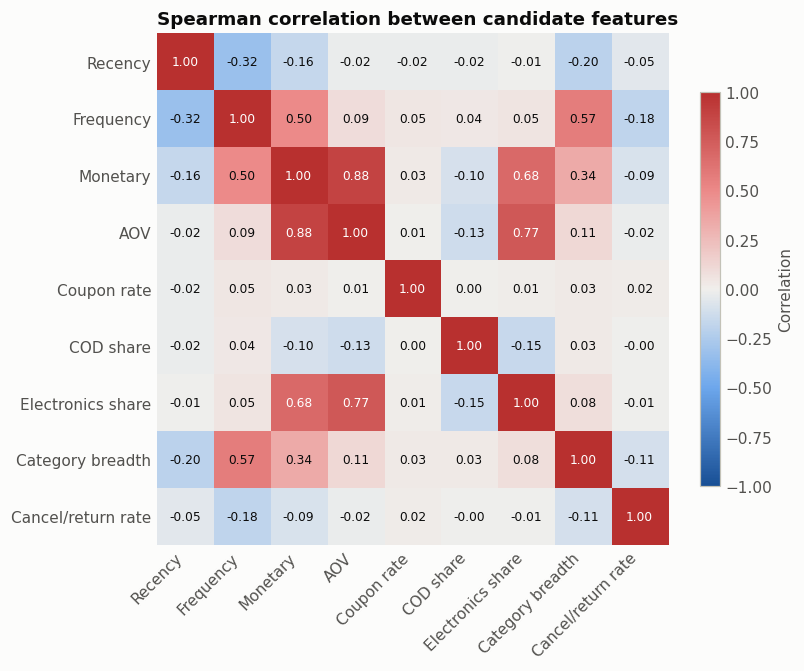

,level_0,level_1,rho,abs_rho
21,monetary,aov,0.88,0.88
33,aov,electronics_share,0.77,0.77
24,monetary,electronics_share,0.68,0.68
16,frequency,category_breadth,0.57,0.57
11,frequency,monetary,0.50,0.50
25,monetary,category_breadth,0.34,0.34
1,recency_days,frequency,-0.32,0.32
7,recency_days,category_breadth,-0.20,0.20


In [16]:
TRANSFORMED = buyers[CLUSTER_CANDIDATES].copy()
for col in ["frequency", "monetary", "aov"]:
    TRANSFORMED[col] = np.log1p(TRANSFORMED[col])

corr = TRANSFORMED.corr(method="spearman")
labels = ["Recency", "Frequency", "Monetary", "AOV", "Coupon rate", "COD share",
          "Electronics share", "Category breadth", "Cancel/return rate"]

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr.values, cmap=ps.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else ps.TEXT_PRIMARY)
ax.set_title("Spearman correlation between candidate features")
fig.colorbar(im, ax=ax, shrink=0.75, label="Correlation")
ps.save(fig, "nb01_feature_correlation")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().assign(abs_rho=lambda d: d.rho.abs())
         .sort_values("abs_rho", ascending=False))
pairs.head(8)

**Finding:** three pairs of features are strongly related:

| Pair | Spearman ρ |
|---|---|
| Monetary – AOV | **0.88** |
| AOV – Electronics share | **0.77** |
| Monetary – Electronics share | 0.68 |

Frequency and category breadth are moderately related (0.57). Coupon rate, COD share and cancel/return rate are almost unrelated to everything else.

**Implication:** Monetary and AOV measure nearly the same thing, because spend is simply Frequency × AOV. Clustering on both would count basket size twice. And because Electronics orders are so much larger, Electronics share largely explains AOV.

**Decision for NB03:** cluster on **log Frequency and log AOV instead of log Monetary**. Since log Monetary = log Frequency + log AOV, no information is lost, the double-counting is removed, and AOV stays in the model as the project requires. A plain log is used for these features in NB03 (every customer clustered has at least one valid order and spend above zero), so the identity holds exactly. Monetary is still used for the rule-based RFM baseline (NB02) and for describing every segment. The AOV – Electronics share overlap is tested in NB03 by clustering with and without Electronics share and comparing the results.

## 5. Save the feature tables

In [17]:
full.to_csv(OUTPUT_DIR / "customer_features_full.csv")
calib.to_csv(OUTPUT_DIR / "customer_features_calibration.csv")
print("Saved:")
for f in ["customer_features_full.csv", "customer_features_calibration.csv"]:
    print(f"  01_data/output/{f}  ({(OUTPUT_DIR / f).stat().st_size / 1e6:.1f} MB)")

Saved:
  01_data/output/customer_features_full.csv  (7.8 MB)
  01_data/output/customer_features_calibration.csv  (7.3 MB)


## 6. Summary

### Answers to the charter's data questions

| # | Question | Answer *[NB01]* |
|---|---|---|
| Q1 | Orders per customer over 25 months; single-order customers | Mean 6.26, median 6; only 483 (1.2%) have one order in their whole history |
| Q2 | Of the 13,404 one-time buyers in Jan–Jun 2026, how many had bought before? | 13,287 (99.1%), with a median of 5 earlier orders; 117 were genuinely new |
| Q3 | Customers active Jun 2024 – Dec 2025 with no order in Jan–Jun 2026 | 9,074 of 39,640 (22.9%), holding ₹953.9 M (23.5%) of calibration spend |
| Q4 | Recency at 30 Jun 2026 | Median 84 days; quartiles 34 and 169 days; 90th percentile 278 days |
| Q5 | Skew in spend per customer | Skewness 1.40 raw, −1.18 after log; top 10% of customers produce 28.8% of spend |
| Q6 | Electronics share of orders; customers never or only buying it | 26.7% of valid orders, 72.6% of revenue; 12,758 (32.0%) never buy it, 677 (1.7%) buy nothing else, 4,992 (12.5%) are Electronics-led |
| Q7 | Categories per customer | 1: 6.0%, 2: 33.1%, 3: 60.9%; nobody buys from more than 3 of 7 |
| Q8 | Coupon vs non-coupon order value; customers never using coupons | ₹24,300 vs ₹23,884 (+1.7%, not commercially meaningful); 11,276 (28.3%) never use coupons |
| Q9 | Cancel/return rate by payment method | About 10% for every method; no relationship (p = 0.962) |

### What this changes for the rest of the project

1. **The retention problem is slowing down, not failing to return.** Almost every customer has bought several times. The focus for NB04 is customers whose buying has slowed or stopped, and Recency is the key signal.
2. **One in four customers went quiet for all of Jan–Jun 2026**, carrying 23.5% of calibration spend. That is the size of the problem the lapse-risk work must explain.
3. **Basket size and Electronics are closely linked.** Clustering will use Frequency and AOV rather than Monetary, and the overlap with Electronics share is tested in NB03.
4. **Payment mode and coupons are not risk or basket-size drivers**, but they vary enough between customers to describe behaviour.

### Feature table saved

`01_data/output/customer_features_full.csv` (39,914 customers) and `01_data/output/customer_features_calibration.csv` (39,640 customers), one row per customer with 24 columns. Column definitions are in [`feature_dictionary.md`](../02_documentation/feature_dictionary.md).